# 12장 실습. 벤치마크: Jev·Laya·AnyJev·LLM

8장의 평가셋(800건)과 채점 방법으로 엔진을 같은 자로 잰다. Jev 와 TF-IDF 기준선은 8장 기록을 그대로 쓰고, 사내 GPU 의 엔진 셋을 이 노트북에서 새로 잰다.

| 엔진 | 어디서 | 기록 이름 |
|---|---|---|
| Jev | 8장 기록 | `jev` |
| TF-IDF 기준선 | 8장 기록 | `tfidf-baseline` |
| Laya (Router → 한국어는 multilingual) | 이 노트북 | `laya-routed` |
| AnyJev 방식 (로컬 LLM 의 첫 토큰 확률, 순환 순열) | 이 노트북 | `anyjev` |
| 로컬 LLM (글로 묻고, 스스로 적은 확신) | 이 노트북 | `llm-gen` |

AnyJev 와 로컬 LLM 은 **같은 모델**이다. 하나는 첫 토큰의 확률을 읽고, 다른 하나는 답과 확신을 글로 쓰게 한다. 같은 LLM 을 결정 엔진으로 쓸 때와 생성기로 쓸 때를 견주는 것이다.

| 절 | 내용 |
|---|---|
| 12.1 | Laya·AnyJev·로컬 LLM 으로 평가셋 800건을 잰다 |
| 12.2 | 다섯 엔진의 결과표 |
| 12.3 | Jev 와 짝지어 비교한다 |
| 12.4 | 온도 재보정 — 반으로 나눠 맞추고 나머지에서 잰다 |
| 12.5 | 재보정 뒤 신뢰도 도표 |
| 12.6 | 기권 정책 — 임계값별 처리율과 오류율 |

Jev 키는 필요 없다(8장 기록을 읽는다). 8장을 먼저 돌려 `results/eval_v1/` 에 `jev`·`tfidf-baseline` 기록이 있어야 한다.

In [1]:
import os, json, time, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
import koreanize_matplotlib  # noqa: F401
from dotenv import load_dotenv
from requests.adapters import HTTPAdapter, Retry

load_dotenv()
DATA, OUT = Path("data"), Path("out")
OUT.mkdir(exist_ok=True)
TASKS = ["topic", "entails", "positive", "similarity"]
COLOR = {"topic": "#2a78d6", "entails": "#eb6834", "positive": "#1baf7a", "similarity": "#eda100"}
pd.set_option("display.precision", 3)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
read_jsonl = lambda p: [json.loads(l) for l in Path(p).read_text(encoding="utf-8").splitlines() if l.strip()]

assert (DATA / "eval_v1.jsonl").exists(), "평가셋이 없다. nb00_setup → nb08_evaluation 을 먼저 실행한다"

def probs_of(answer):
    return answer.get("probabilities") or {"true": answer["noul"], "false": 1 - answer["noul"]}

def judge(item, resp):
    (task, q), = item["questions"].items()
    a = resp["answers"][task]
    pr = {str(k): float(v) for k, v in probs_of(a).items()}
    best = max(pr, key=pr.get)
    pred = {"noul": lambda: pr["true"] >= 0.5, "choice": lambda: best, "score": lambda: int(best)}[q["type"]]()
    return {"id": item["id"], "task": item["task"], "qtype": q["type"], "gold": item["gold"], "model": resp["model"],
            "pred": pred, "probs": pr, "conf": pr[best], "conf_field": a.get("confidence"), "correct": bool(pred == item["gold"]),
            "input_tokens": resp["usage"]["input_tokens"], "latency_s": resp["_latency_s"]}

def run(items, engine=lambda it: ask(it["state"], it["questions"]), workers=4):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(lambda it: judge(it, engine(it)), items))

arrays = lambda recs: (np.array([r["conf"] for r in recs]), np.array([r["correct"] for r in recs], float))

def ece(conf, ok, bins=15):
    idx = np.clip(np.searchsorted(np.linspace(0, 1, bins + 1), conf, side="left") - 1, 0, bins - 1)
    return float(sum(abs(conf[idx == i].mean() - ok[idx == i].mean()) * (idx == i).sum() for i in np.unique(idx)) / len(conf))

RESULTS = Path("results/eval_v1")
items = read_jsonl(DATA / "eval_v1.jsonl")
card = json.loads((DATA / "eval_v1.card.json").read_text(encoding="utf-8"))
write_jsonl = lambda p, rows: Path(p).write_text("".join(json.dumps(r, ensure_ascii=False, default=str) + "\n" for r in rows), encoding="utf-8")

def coverage_at_risk(conf, ok, risk=0.05):
    order = np.argsort(-conf, kind="stable")
    c, y, k = conf[order], ok[order], np.arange(1, len(conf) + 1)
    return float(np.max(k[np.append(c[1:] != c[:-1], True) & (np.cumsum(1 - y) / k <= risk)], initial=0) / len(conf))

def summarize(recs):
    conf, ok = arrays(recs)
    return {"n": len(recs), "accuracy": ok.mean(), "mean_conf": conf.mean(), "ece": ece(conf, ok), "coverage@5%": coverage_at_risk(conf, ok),
            "latency_p50_ms": 1000 * np.median([r["latency_s"] for r in recs])}

report = lambda recs: pd.DataFrame({t: summarize([r for r in recs if r["task"] == t]) for t in TASKS} | {"ALL": summarize(recs)}).T

def measure(name, engine, workers=1):
    t0 = time.perf_counter()
    recs = run(items, engine, workers=workers)
    write_jsonl(RESULTS / f"{name}.records.jsonl", recs)
    print(f"{name:<12} {time.perf_counter() - t0:6.0f}초 | 모델 {sorted({r['model'] for r in recs})}")
    return recs

## 12.1 평가셋 측정: Laya·AnyJev·로컬 LLM

엔진 자리에 함수만 바꿔 꽂는다. 채점·저장은 8장과 같다. GPU 메모리를 위해 Laya 를 재고 내린 뒤 로컬 LLM 을 올린다.

In [2]:
import laya
from laya import Router

router = Router()                          # 한국어는 multilingual 체크포인트로 간다(10장)

def laya_post(state, questions):
    t0 = time.perf_counter()
    r = router.predict(state, questions)
    return r | {"model": "laya:" + r["routing"]["model"], "usage": {"input_tokens": 0}, "_latency_s": time.perf_counter() - t0}
print("laya", laya.__version__)

laya_rec = measure("laya-routed", lambda it: laya_post(it["state"], it["questions"]))
del router

laya 0.4.7


/home/josh/anaconda3/envs/pytorch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 2583.97it/s]


laya-routed      18초 | 모델 ['laya:multilingual']


In [3]:
from transformers import AutoModelForCausalLM, AutoTokenizer

LLM_MODEL = os.environ["LOCAL_LLM_MODEL"]
tok = AutoTokenizer.from_pretrained(LLM_MODEL, padding_side="left")
tok.pad_token = tok.pad_token or tok.eos_token
lm = AutoModelForCausalLM.from_pretrained(LLM_MODEL, dtype="auto", device_map="auto")

def chat_batch(prompts, max_new_tokens=256, batch_size=16, system=None):
    # 프롬프트 여럿을 묶어 generate 한 번에 보낸다(왼쪽 패딩). 서빙 엔진 없이 처리량을 내는 방법이다
    msgs = lambda p: [{"role": "system", "content": system}] * bool(system) + [{"role": "user", "content": p}]
    texts = [tok.apply_chat_template(msgs(p), tokenize=False, add_generation_prompt=True, enable_thinking=False) for p in prompts]
    outs = []
    for i in range(0, len(texts), batch_size):
        enc = tok(texts[i:i + batch_size], return_tensors="pt", padding=True).to(lm.device)
        gen = lm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
        outs += tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs]

chat = lambda prompt, **kw: chat_batch([prompt], **kw)[0]
print(LLM_MODEL, "|", lm.device)

import torch

LETTERS = "ABCDEFGHIJ"
letter_ids = [tok.encode(c, add_special_tokens=False)[0] for c in LETTERS]
OPTIONS = {"choice": lambda c: [(k, f"{k}: {v}") for k, v in c.items()],
           "score": lambda c: [(str(i), lv) for i, lv in enumerate(c)],
           "noul": lambda c: [("true", f"참. {c.get('true', '')}"), ("false", f"거짓. {c.get('false', '')}")]}

def anyjev_prompt(state, q, texts, order):
    menu = "\n".join(f"{LETTERS[s]}. {texts[j]}" for s, j in enumerate(order))
    user = f"[판단할 대상]\n{json.dumps(state, ensure_ascii=False)}\n\n[질문]\n{q['instructions']}\n{menu}\n\n답(기호 한 글자):"
    msgs = [{"role": "system", "content": "너는 판단만 하는 분류기다. 질문을 읽고 선택지 기호 한 글자로만 답한다."}, {"role": "user", "content": user}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)

def rotations(state, q, cyclic=True):
    # 선택지 순서를 한 칸씩 돌린 k 개 프롬프트를 한 배치로 보내고, 첫 토큰에서 기호들의 로그 확률을 읽는다
    keys, texts = zip(*OPTIONS[q["type"]](q.get("criteria") or {}))
    k = len(keys)
    orders = np.array([[(i + s) % k for i in range(k)] for s in range(k if cyclic else 1)])
    enc = tok([anyjev_prompt(state, q, texts, o) for o in orders], return_tensors="pt", padding=True).to(lm.device)
    with torch.no_grad():
        logits = lm(**enc).logits[:, -1].float()
    slot = torch.log_softmax(logits, -1)[:, letter_ids[:k]].cpu().numpy()       # [회전, 자리]
    R = np.zeros_like(slot)
    np.put_along_axis(R, orders, slot, axis=1)                                  # 자리 → 원래 선택지 순서
    return list(keys), R, int(enc["attention_mask"].sum())

ANSWER = {"noul": lambda keys, p: {"type": "noul", "noul": float(p[keys.index("true")])},
          "choice": lambda keys, p: {"type": "choice", "choice": keys[int(p.argmax())], "probabilities": dict(zip(keys, map(float, p)))},
          "score": lambda keys, p: {"type": "score", "score": float(np.dot(np.arange(len(p)), p)), "probabilities": dict(zip(keys, map(float, p)))}}

def anyjev(state, questions):
    t0, answers, tokens = time.perf_counter(), {}, 0
    for name, q in questions.items():
        keys, R, n = rotations(state, q)
        p = np.exp(R.mean(0) - R.mean(0).max())                                 # 회전 평균 로그 확률 → 확률
        answers[name], tokens = ANSWER[q["type"]](keys, p / p.sum()), tokens + n
    return {"model": "anyjev:" + LLM_MODEL, "answers": answers, "usage": {"input_tokens": tokens}, "_latency_s": time.perf_counter() - t0}

import re

KEYS = {"choice": lambda q: list(q["criteria"]), "score": lambda q: [str(i) for i in range(len(q["criteria"]))], "noul": lambda q: ["true", "false"]}
LINES = {"choice": lambda q: [f"  {k}: {v}" for k, v in q["criteria"].items()],
         "score": lambda q: [f"  {i}: {v}" for i, v in enumerate(q["criteria"])],
         "noul": lambda q: [f"  {k}: {v}" for k, v in (q.get("criteria") or {"true": "그렇다", "false": "아니다"}).items()]}

def gen_prompt(state, q):
    return "\n".join(["[판단할 대상]", json.dumps(state, ensure_ascii=False), "", "[질문]", q["instructions"], "[선택지]", *LINES[q["type"]](q), "",
                       "선택지 키 하나와, 그 답이 맞을 확률을 아래 두 줄 형식으로만 답하라.", "답: <선택지 키>", "확신: <0과 1 사이 숫자>"])

def gen_answer(q, text):
    keys = KEYS[q["type"]](q)
    ans = (re.findall(r"답\s*[:：]\s*(\S+)", text) + [None])[0]
    conf = float((re.findall(r"확신\s*[:：]\s*([01](?:\.\d+)?)", text) + ["nan"])[0])
    p = {k: [(1 - conf) / (len(keys) - 1), conf][k == ans] for k in keys} if ans in keys and conf == conf else {k: 1 / len(keys) for k in keys}
    return {"type": q["type"], "probabilities": p, "noul": p.get("true"), "choice": max(p, key=p.get), "invalid": ans not in keys, "raw": text}

def gen_many(states_questions, batch_size=16):
    # (state, 질문 하나짜리 dict) 목록을 묶어서 생성하고 Jev 모양의 응답으로 바꾼다
    flat = [(s, n, q) for s, qs in states_questions for n, q in qs.items()]
    t0 = time.perf_counter()
    outs = chat_batch([gen_prompt(s, q) for s, _, q in flat], max_new_tokens=24, batch_size=batch_size)
    sec = (time.perf_counter() - t0) / len(flat)
    return [{"model": "llm:" + LLM_MODEL, "answers": {n: gen_answer(q, o)}, "usage": {"input_tokens": 0}, "_latency_s": sec}
            for (s, n, q), o in zip(flat, outs)]

anyjev_rec = measure("anyjev", lambda it: anyjev(it["state"], it["questions"]))

Ignoring corrupted tree cache file /data/shared/hf/hub/models--Qwen--Qwen3.5-4B/trees/851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a.json: [Errno 13] Permission denied: '/data/shared/hf/hub/models--Qwen--Qwen3.5-4B/trees/851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a.json'
Loading weights: 100%|██████████| 426/426 [00:01<00:00, 378.05it/s]
[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


Qwen/Qwen3.5-4B | cuda:0
anyjev           70초 | 모델 ['anyjev:Qwen/Qwen3.5-4B']


로컬 LLM 은 800건을 묶어서 생성한다. 답과 확신을 두 줄 형식으로 쓰게 하고 정규식으로 읽는다. 형식을 어기면 그 항목은 확률을 고르게 나눠 둔다(사실상 기권). 몇 건이 그랬는지 함께 센다.

In [4]:
t0 = time.perf_counter()
gen = gen_many([(it["state"], it["questions"]) for it in items])
llm_rec = [judge(it, g) | {"invalid": g["answers"][it["task"]]["invalid"]} for it, g in zip(items, gen)]
write_jsonl(RESULTS / "llm-gen.records.jsonl", llm_rec)
print(f"llm-gen {time.perf_counter() - t0:.0f}초 | 형식 어김 {sum(r['invalid'] for r in llm_rec)}건 / {len(llm_rec)}")
del lm; torch.cuda.empty_cache()

[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


llm-gen 45초 | 형식 어김 1건 / 800


## 12.2 엔진별 결과표

`results/eval_v1/` 의 기록을 모두 읽어 같은 지표로 놓는다. 정확도는 다수결 비율(topic 0.405, entails 0.670, positive 0.505, similarity 0.235)과 견줘 읽는다(8.1절).

In [5]:
recs = {p.name.replace(".records.jsonl", ""): read_jsonl(p) for p in sorted(RESULTS.glob("*.records.jsonl"))}
table = pd.concat({name: report(r) for name, r in recs.items()}).swaplevel().sort_index().loc[TASKS + ["ALL"]]
table

n  accuracy  mean_conf    ece  coverage@5%  \
topic      anyjev          200.0     0.765      0.868  0.120        0.390   
           jev             200.0     0.800      0.897  0.102        0.565   
           laya-routed     200.0     0.340      0.663  0.323        0.000   
           llm-gen         200.0     0.755      0.948  0.193        0.040   
           tfidf-baseline  200.0     0.815      0.710  0.122        0.300   
entails    anyjev          200.0     0.940      0.869  0.079        0.955   
           jev             200.0     0.975      0.919  0.061        1.000   
           laya-routed     200.0     0.880      0.948  0.110        0.550   
           llm-gen         200.0     0.910      0.999  0.089        0.000   
           tfidf-baseline  200.0     0.675      0.682  0.045        0.030   
positive   anyjev          200.0     0.790      0.876  0.097        0.265   
           jev             200.0     0.850      0.831  0.036        0.665   
           laya-routed     200.0     0.665      0.779  0.146        0.005   
           llm-gen         200.0     0.780      0.969  0.189        0.385   
           tfidf-baseline  200.0     0.820      0.816  0.037        0.480   
similarity anyjev          200.0     0.250      0.470  0.225        0.015   
           jev             200.0     0.350      0.621  0.275        0.005   
           laya-routed     200.0     0.140      0.328  0.188        0.000   
           llm-gen         200.0     0.310      0.936  0.626        0.000   
           tfidf-baseline  200.0     0.305      0.513  0.239        0.005   
ALL        anyjev          800.0     0.686      0.771  0.084        0.285   
           jev             800.0     0.744      0.817  0.073        0.507   
           laya-routed     800.0     0.506      0.679  0.173        0.126   
           llm-gen         800.0     0.689      0.963  0.274        0.000   
           tfidf-baseline  800.0     0.654      0.680  0.048        0.185   

                           latency_p50_ms  
topic      anyjev                 123.457  
           jev                    178.909  
           laya-routed             13.382  
           llm-gen                 56.190  
           tfidf-baseline           0.509  
entails    anyjev                  66.252  
           jev                    174.133  
           laya-routed             13.499  
           llm-gen                 56.190  
           tfidf-baseline           1.715  
positive   anyjev                  62.551  
           jev                    170.163  
           laya-routed             13.663  
           llm-gen                 56.190  
           tfidf-baseline           0.486  
similarity anyjev                  91.800  
           jev                    177.325  
           laya-routed             13.675  
           llm-gen                 56.190  
           tfidf-baseline           0.954  
ALL        anyjev                  82.346  
           jev                    175.308  
           laya-routed             13.530  
           llm-gen                 56.190  
           tfidf-baseline           0.882

In [6]:
# similarity(6단계)는 정확히 맞힌 비율보다 평균 절대 오차와 한 단계 안 비율로 본다
gold_value = {i["id"]: i["gold_value"] for i in items if i["task"] == "similarity"}
pd.DataFrame({name: {"정확도": np.mean([x["correct"] for x in r if x["task"] == "similarity"]),
                     "평균 절대 오차": np.mean([abs(sum(int(k) * v for k, v in x["probs"].items()) - gold_value[x["id"]]) for x in r if x["task"] == "similarity"]),
                     "한 단계 안": np.mean([abs(x["pred"] - x["gold"]) <= 1 for x in r if x["task"] == "similarity"])} for name, r in recs.items()}).T

,정확도,평균 절대 오차,한 단계 안
anyjev,0.250,1.015,0.705
jev,0.350,0.699,0.880
laya-routed,0.140,1.240,0.450
llm-gen,0.310,0.976,0.760
tfidf-baseline,0.305,1.139,0.605


## 12.3 Jev 대비 짝지은 비교

같은 항목을 짝지어 복원 추출한다(8.10절). 구간이 0 을 걸치지 않아야 차이가 있다고 말한다.

In [7]:
def paired(a, b_, n_boot=2000, seed=0):
    ib = {r["id"]: r for r in b_}
    ca, cb = np.array([r["correct"] for r in a], float), np.array([ib[r["id"]]["correct"] for r in a], float)
    d = cb[(idx := np.random.default_rng(seed).integers(0, len(ca), (n_boot, len(ca))))].mean(1) - ca[idx].mean(1)
    return {"Jev": ca.mean(), "엔진": cb.mean(), "차이 (엔진 − Jev)": f"{cb.mean() - ca.mean():+.3f} ({np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f})",
            "답이 갈린 항목": int((ca != cb).sum())}

by_task = lambda r, t: [x for x in r if x["task"] == t]
pd.DataFrame({(name, t): paired(by_task(recs["jev"], t), by_task(r, t)) for name, r in recs.items() if name != "jev" for t in TASKS}).T

Jev     엔진            차이 (엔진 − Jev) 답이 갈린 항목
anyjev         topic         0.8  0.765  -0.035 (-0.085, +0.010)       23
               entails     0.975   0.94  -0.035 (-0.075, +0.000)       15
               positive     0.85   0.79  -0.060 (-0.110, -0.010)       28
               similarity   0.35   0.25  -0.100 (-0.175, -0.025)       60
laya-routed    topic         0.8   0.34  -0.460 (-0.535, -0.385)      100
               entails     0.975   0.88  -0.095 (-0.145, -0.050)       23
               positive     0.85  0.665  -0.185 (-0.260, -0.110)       61
               similarity   0.35   0.14  -0.210 (-0.300, -0.125)       84
llm-gen        topic         0.8  0.755  -0.045 (-0.095, +0.005)       29
               entails     0.975   0.91  -0.065 (-0.110, -0.025)       19
               positive     0.85   0.78  -0.070 (-0.125, -0.015)       34
               similarity   0.35   0.31  -0.040 (-0.115, +0.030)       54
tfidf-baseline topic         0.8  0.815  +0.015 (-0.055, +0.085)       51
               entails     0.975  0.675  -0.300 (-0.370, -0.235)       66
               positive     0.85   0.82  -0.030 (-0.080, +0.020)       26
               similarity   0.35  0.305  -0.045 (-0.135, +0.045)       87

## 12.4 온도 재보정과 cross-fit

Laya 문서는 체크포인트가 과신하며 multilingual 에는 맞춘 온도가 없다고 밝혔다. 엔진·과제마다 온도 T 하나를 맞춘다. 확률 p 를 p^(1/T) 로 바꾼 뒤 합이 1 이 되게 나눈다. T 가 1 보다 크면 분포가 퍼지고(과신을 누른다) 작으면 모인다. 정답의 음의 로그 우도를 가장 작게 하는 T 를 찾는다.

200건을 반으로 나눠 한쪽에서 T 를 맞추고 다른 쪽에 적용한 뒤 바꿔서 한 번 더 한다(cross-fit). 어느 항목도 자기 라벨로 맞춘 T 를 받지 않는다. 가장 확률이 높은 답은 T 로 바뀌지 않으므로 정확도는 그대로다.

In [8]:
from scipy.optimize import minimize_scalar
from scipy.special import log_softmax

gold_key = lambda r: {"noul": lambda: ["false", "true"][r["gold"]], "choice": lambda: r["gold"], "score": lambda: str(r["gold"])}[r["qtype"]]()
logp = lambda r: np.log(np.clip(list(r["probs"].values()), 1e-6, 1))

def fit_temperature(rs):
    rows = [(logp(r), list(r["probs"]).index(gold_key(r))) for r in rs]
    return minimize_scalar(lambda T: -np.mean([log_softmax(lp / T)[g] for lp, g in rows]), bounds=(0.05, 20.0), method="bounded").x

apply_temperature = lambda rs, T: [r | {"conf": float(np.exp(log_softmax(logp(r) / T)).max())} for r in rs]

def cross_fit(rs, seed=0):
    idx = np.random.default_rng(seed).permutation(len(rs))
    a, b_ = [rs[i] for i in idx[: len(rs) // 2]], [rs[i] for i in idx[len(rs) // 2:]]
    return apply_temperature(a, fit_temperature(b_)) + apply_temperature(b_, fit_temperature(a))

calibrated = {name: [x for t in TASKS for x in cross_fit(by_task(r, t))] for name, r in recs.items()}
pd.DataFrame([{"엔진": name, "과제": t, "T (전체로 맞춘 값)": fit_temperature(by_task(r, t)),
               "ECE 전": ece(*arrays(by_task(r, t))), "ECE 후": ece(*arrays(by_task(calibrated[name], t))),
               "처리율@5% 전": coverage_at_risk(*arrays(by_task(r, t))), "처리율@5% 후": coverage_at_risk(*arrays(by_task(calibrated[name], t)))}
              for name, r in recs.items() for t in TASKS]).set_index(["엔진", "과제"])

T (전체로 맞춘 값)  ECE 전  ECE 후  처리율@5% 전  처리율@5% 후
엔진             과제                                                        
anyjev         topic              1.432  0.120  0.059     0.390     0.145
               entails            0.530  0.079  0.044     0.955     0.955
               positive           1.905  0.097  0.048     0.265     0.305
               similarity         2.383  0.225  0.071     0.015     0.010
jev            topic              2.477  0.102  0.056     0.565     0.545
               entails            0.450  0.061  0.014     1.000     1.000
               positive           0.773  0.036  0.050     0.665     0.665
               similarity         3.380  0.275  0.055     0.005     0.015
laya-routed    topic              2.577  0.323  0.056     0.000     0.000
               entails            2.164  0.110  0.055     0.550     0.555
               positive           2.273  0.146  0.064     0.005     0.015
               similarity         8.352  0.188  0.045     0.000     0.000
llm-gen        topic              1.640  0.193  0.002     0.040     0.040
               entails            5.852  0.089  0.005     0.000     0.000
               positive           4.134  0.189  0.019     0.385     0.385
               similarity         5.934  0.626  0.070     0.000     0.000
tfidf-baseline topic              0.748  0.122  0.105     0.300     0.330
               entails            1.043  0.045  0.059     0.030     0.010
               positive           1.057  0.037  0.059     0.480     0.385
               similarity         2.607  0.239  0.135     0.005     0.005

## 12.5 재보정 후 신뢰도 도표

재보정한 확신으로 과제별 신뢰도 도표를 그린다. 점이 대각선에 가까울수록 확신을 믿을 수 있다.

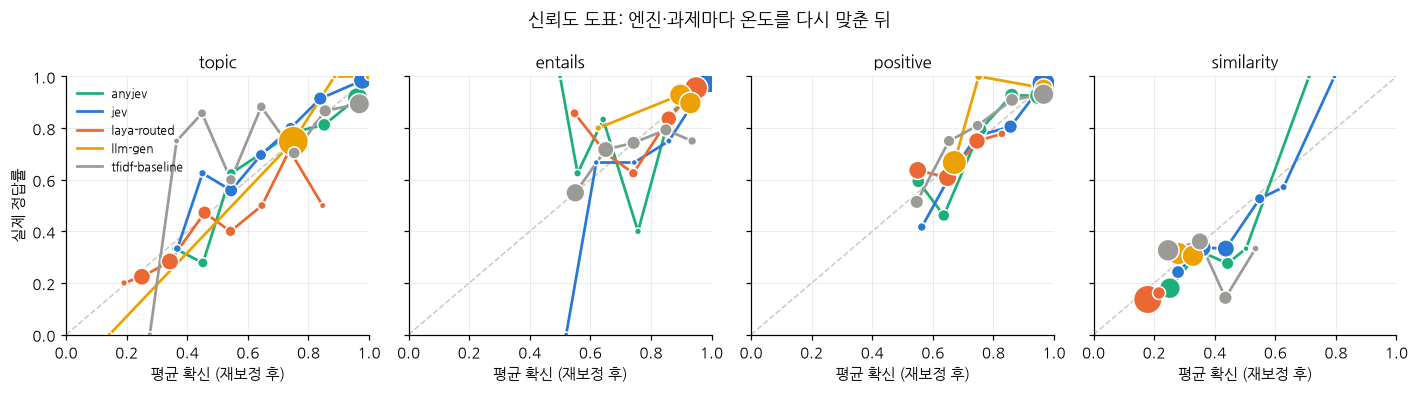

In [9]:
PALETTE = {"jev": "#2a78d6", "tfidf-baseline": "#9a9a96", "laya-routed": "#eb6834", "anyjev": "#1baf7a", "llm-gen": "#eda100"}

def reliability(rs, bins=10):
    conf, ok = arrays(rs)
    idx = np.clip(np.searchsorted(np.linspace(0, 1, bins + 1), conf, side="left") - 1, 0, bins - 1)
    return [(conf[idx == i].mean(), ok[idx == i].mean(), (idx == i).sum()) for i in np.unique(idx)]

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), dpi=110, sharey=True)
for ax, t in zip(axes, TASKS):
    ax.plot([0, 1], [0, 1], ls="--", lw=1, color="#c9c9c5")
    for name, rs in calibrated.items():
        x, y, n = zip(*reliability(by_task(rs, t)))
        ax.plot(x, y, lw=1.8, color=PALETTE.get(name, "#3d3d3a"), label=name)
        ax.scatter(x, y, s=[10 + 2 * k for k in n], color=PALETTE.get(name, "#3d3d3a"), edgecolor="white", linewidth=1, zorder=3)
    ax.set_title(t, fontsize=11); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel("평균 확신 (재보정 후)"); ax.grid(alpha=0.25, lw=0.6)
axes[0].set_ylabel("실제 정답률"); axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("신뢰도 도표: 엔진·과제마다 온도를 다시 맞춘 뒤", fontsize=12)
fig.tight_layout(); fig.savefig(OUT / "nb12_reliability_calibrated.png", bbox_inches="tight"); plt.show()

## 12.6 기권 정책과 처리율–오류율

임계값을 넘는 답만 자동 처리하고 나머지는 사람에게 보낸다(Laya 의 `min_confidence`, 5.2절의 게이트와 같은 정책). 재보정한 확신으로 임계값마다 처리율과 처리분 오류율을 낸다.

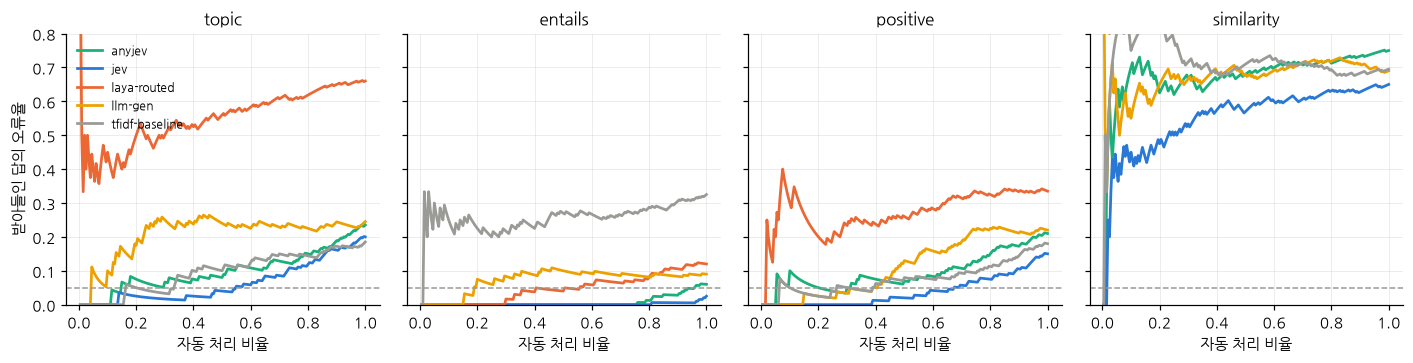

처리율 @0.7  처리율 @0.8  처리율 @0.9  오류율 @0.7  오류율 @0.8  \
positive anyjev             0.710     0.540     0.335     0.106     0.074   
         jev                0.810     0.745     0.565     0.080     0.067   
         laya-routed        0.325     0.045     0.000     0.246     0.222   
         llm-gen            0.385     0.335     0.335     0.039     0.045   
         tfidf-baseline     0.705     0.600     0.435     0.092     0.075   
topic    anyjev             0.700     0.585     0.425     0.129     0.111   
         jev                0.630     0.505     0.330     0.071     0.040   
         laya-routed        0.055     0.020     0.000     0.364     0.500   
         llm-gen            0.995     0.040     0.035     0.241     0.000   
         tfidf-baseline     0.710     0.575     0.425     0.148     0.113   

                         오류율 @0.9  
positive anyjev             0.075  
         jev                0.027  
         laya-routed          NaN  
         llm-gen            0.045  
         tfidf-baseline     0.069  
topic    anyjev             0.082  
         jev                0.015  
         laya-routed          NaN  
         llm-gen            0.000  
         tfidf-baseline     0.106

In [10]:
def risk_curve(rs):
    conf, ok = arrays(rs)
    order, k = np.argsort(-conf, kind="stable"), np.arange(1, len(conf) + 1)
    return k / len(conf), np.cumsum(1 - ok[order]) / k

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), dpi=110, sharey=True)
for ax, t in zip(axes, TASKS):
    for name, rs in calibrated.items():
        ax.plot(*risk_curve(by_task(rs, t)), lw=1.8, color=PALETTE.get(name, "#3d3d3a"), label=name)
    ax.axhline(0.05, ls="--", lw=1, color="#9a9a96"); ax.set_title(t, fontsize=11); ax.set_xlabel("자동 처리 비율"); ax.set_ylim(0, 0.8); ax.grid(alpha=0.25, lw=0.6)
axes[0].set_ylabel("받아들인 답의 오류율"); axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(OUT / "nb12_coverage_risk.png", bbox_inches="tight"); plt.show()

def thresholds(rs, ts=(0.7, 0.8, 0.9)):
    conf, ok = arrays(rs)
    return {**{f"처리율 @{t}": (conf >= t).mean() for t in ts}, **{f"오류율 @{t}": pd.Series(1 - ok[conf >= t]).mean() for t in ts}}

pd.DataFrame({(t, name): thresholds(by_task(rs, t)) for name, rs in calibrated.items() for t in ["topic", "positive"]}).T.sort_index()

## 정리

이 노트북이 잰 것이다. 결과 해석은 12장 본문에서 한다.

- 12.1 Laya·AnyJev·로컬 LLM 의 평가셋 800건 기록과 로컬 LLM 의 형식 어김 건수
- 12.2 엔진별·과제별 정확도·평균 확신·ECE·처리율@5%·지연, similarity 의 오차
- 12.3 Jev 와 짝지은 정확도 차이와 구간
- 12.4 엔진·과제별 온도와 재보정 전후의 ECE·처리율@5%
- 12.5 재보정 뒤 신뢰도 도표, 12.6 처리율–오류율 곡선과 임계값별 표